## Onset speed (development)

Fish speed and tail speed at the onset of movement across development. 

Figures are saved to the project `figures/` directory and to `onset_speed/media/`.

Import libraries:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
def inline():
    %matplotlib inline
    plt.close('all')
def widget():
    %matplotlib widget
    plt.close('all')
import sys
from pathlib import Path
_code = Path.cwd() if (Path.cwd() / "paths.py").exists() else Path.cwd().parent
if str(_code.resolve()) not in [str(Path(p).resolve()) for p in sys.path]:
    sys.path.insert(0, str(_code.resolve()))
from paths import PROJECT_ROOT, DATA_DIR, FIGURES_DIR, notebook_media_dir
%load_ext autoreload
%autoreload 2
    
#from functions.visual_flow_behavior_plotting import *
#from functions.visual_flow_behavior_analysis import *
#from functions.brain_analysis import *
from functions.utilities import *
#from functions.feedback_models import *
from functions.freely_swimming import *
from functions.MC_freely_swimming import *
from functions.MC_plots import *
from functions.MC_utilities import *

import os
import h5py
from ipywidgets import interact,IntSlider
from scipy import fft
from scipy.ndimage import gaussian_filter
from skimage import io
import pickle
from scipy import fft
from sklearn.preprocessing import scale
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
from scipy.stats import iqr
import pandas as pd
from scipy.interpolate import interp1d
from functions.MC_utilities import *

from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


In [ ]:
from functions.MC_utilities import *
[color_low_eta, color_m, color_high_eta, color_low_boutID, color_med_boutID, color_high_boutID, color_cont, color_bout] = get_colors()
group_colors = [color_low_eta, color_m, color_high_eta]

In [3]:
print(os.getcwd()) 

<repo>/code/onset_speed


In [4]:
# Paths from code/paths.py (project root, data, figures, local media)
path = str(PROJECT_ROOT)
path_data = str(DATA_DIR)
path_figures = str(FIGURES_DIR)
path_media = str(notebook_media_dir("onset_speed"))
print(path, path_data, path_figures)

<repo> <repo>/data <repo>/figures


#### Import data:

In [5]:
#fish_ids_young=['13_06May24_1','13_30Oct24_3','13_30Oct24_4','14_27Mar24_1','14_31Oct24_1']
fish_ids_young=['13_06May24_1','13_30Oct24_3','13_30Oct24_4','14_31Oct24_1']
index_y = list(range(0, len(fish_ids_young)))
print(index_y)

[0, 1, 2, 3]


In [6]:
fish_ids_intermediate=['17_21May24_2','18_22May24_1','18_22May24_2','19_23May24_5','20_05Jun24_1','20_05Jun24_2','20_12Jun24_1','21_06Dec24_1','21_06Dec24_2','21_06Jun24_1','25_10Jun24_1']
index_i = list( range(len(fish_ids_young), len(fish_ids_young)+len(fish_ids_intermediate)) )
print(index_i)

[4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]


In [7]:
#fish_ids_old=['26_02May24_2','27_12Jun24_1','28_04May24_1','30_06May24_2','34_11Dec24_1','34_11Dec24_3']
fish_ids_old=['26_02May24_2','28_04May24_1','30_06May24_2','34_11Dec24_1','34_11Dec24_3']
index_o = list( range( len(fish_ids_young)+len(fish_ids_intermediate) , len(fish_ids_young)+len(fish_ids_intermediate)+len(fish_ids_old) ) )
print(index_o)

[15, 16, 17, 18, 19]


In [8]:
fish_ids=fish_ids_young+fish_ids_intermediate+fish_ids_old

In [9]:
fish_ids

['13_06May24_1',
 '13_30Oct24_3',
 '13_30Oct24_4',
 '14_31Oct24_1',
 '17_21May24_2',
 '18_22May24_1',
 '18_22May24_2',
 '19_23May24_5',
 '20_05Jun24_1',
 '20_05Jun24_2',
 '20_12Jun24_1',
 '21_06Dec24_1',
 '21_06Dec24_2',
 '21_06Jun24_1',
 '25_10Jun24_1',
 '26_02May24_2',
 '28_04May24_1',
 '30_06May24_2',
 '34_11Dec24_1',
 '34_11Dec24_3']

In [10]:
index_groups = {
    '1-2 wpf': index_y,
    '3 wpf': index_i,
    '4-5 wpf': index_o
}

In [11]:
age_list = [int(fid.split('_')[0]) for fid in fish_ids]
print(age_list)

[13, 13, 13, 14, 17, 18, 18, 19, 20, 20, 20, 21, 21, 21, 25, 26, 28, 30, 34, 34]


In [12]:
#SORTING BY ETA
index_cont = [0, 1, 2, 8]
index_mix = [3, 4, 5, 6, 7, 9, 11, 12, 13, 14, 17]
index_bout = [10, 15, 16, 18, 19]

Load:

In [13]:
speed_clean = pd.read_hdf(os.path.join(path_data, f"speed_clean.h5"), key='df')

In [14]:
speed_clean

,ID,t_c,vfish_c,vtail_c,dangletail_c,angletail_c,freqtail_c,mean_thrust_c
0,13_06May24_1,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
1,13_06May24_1,0.003333,NaN,NaN,NaN,NaN,NaN,NaN
2,13_06May24_1,0.006667,NaN,NaN,NaN,NaN,NaN,NaN
3,13_06May24_1,0.010000,NaN,NaN,NaN,NaN,NaN,NaN
4,13_06May24_1,0.013333,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
21727813,34_11Dec24_3,320.736667,NaN,NaN,NaN,NaN,NaN,NaN
21727814,34_11Dec24_3,320.740000,NaN,NaN,NaN,NaN,NaN,NaN
21727815,34_11Dec24_3,320.743333,NaN,NaN,NaN,NaN,NaN,NaN
21727816,34_11Dec24_3,320.746667,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
thrust_thresholds = pd.read_hdf(os.path.join(path_data, f"thrust_thresholds.h5"), key='df')

In [16]:
thrust_thresholds

,ID,thrust_thr,mask_movetail
0,13_06May24_1,0.000331,False
1,13_06May24_1,0.000331,False
2,13_06May24_1,0.000331,False
3,13_06May24_1,0.000331,False
4,13_06May24_1,0.000331,False
...,...,...,...
21727813,34_11Dec24_3,0.025991,False
21727814,34_11Dec24_3,0.025991,False
21727815,34_11Dec24_3,0.025991,False
21727816,34_11Dec24_3,0.025991,False


In [17]:
onsets = pd.read_hdf(os.path.join(path_data, f"onsets.h5"), key='df')

In [20]:
onsets

,ID,onset_indices,initial_vfish,initial_vtail,bout_duration
0,13_06May24_1,1369,6.717492,102.127655,2.566667
1,13_06May24_1,2987,4.772649,90.986139,1.966667
2,13_06May24_1,4877,7.283671,136.008985,1.780000
3,13_06May24_1,5695,6.163918,100.164392,2.900000
4,13_06May24_1,6601,3.750249,69.222574,0.966667
...,...,...,...,...,...
45480,34_11Dec24_3,92811,24.794113,263.748909,0.213333
45481,34_11Dec24_3,92984,35.093076,348.691133,0.213333
45482,34_11Dec24_3,93206,38.267398,332.921438,0.196667
45483,34_11Dec24_3,93407,35.724430,275.439541,0.216667


In [21]:
t_c_list=[]
vfish_c_list=[]
vtail_c_list=[]
mean_thrust_c_list=[]
angletail_c_list=[]
dangletail_c_list=[]
freqtail_c_list=[]

for fish_ID in tqdm(fish_ids):
    speed_clean_fish=subset_by_fish(fish_ID,DF1=speed_clean)[0]
    t_c_list.append(speed_clean_fish['t_c'].values)
    vfish_c_list.append(speed_clean_fish['vfish_c'].values)
    vtail_c_list.append(speed_clean_fish['vtail_c'].values)    
    mean_thrust_c_list.append(speed_clean_fish['mean_thrust_c'].values)
    angletail_c_list.append(speed_clean_fish['angletail_c'].values)
    dangletail_c_list.append(speed_clean_fish['dangletail_c'].values)
    freqtail_c_list.append(speed_clean_fish['freqtail_c'].values)

  0%|          | 0/20 [00:00<?, ?it/s]

Subsetting data of the fish 13_06May24_1


  5%|▌         | 1/20 [00:03<00:58,  3.08s/it]

Subsetting data of the fish 13_30Oct24_3


 10%|█         | 2/20 [00:06<00:58,  3.26s/it]

...

 90%|█████████ | 18/20 [00:53<00:05,  2.87s/it]

Subsetting data of the fish 34_11Dec24_1


 95%|█████████▌| 19/20 [00:56<00:02,  2.92s/it]

Subsetting data of the fish 34_11Dec24_3


100%|██████████| 20/20 [00:59<00:00,  2.97s/it]


In [22]:
thrust_thr_list=[]
mask_movetail_list=[]

for fish_ID in tqdm(fish_ids):
    thrust_thresholds_fish=subset_by_fish(fish_ID,DF1=thrust_thresholds)[0]
    thrust_thr_list.append(thrust_thresholds_fish['thrust_thr'].values[0])
    mask_movetail_list.append(thrust_thresholds_fish['mask_movetail'].values)

  0%|          | 0/20 [00:00<?, ?it/s]

Subsetting data of the fish 13_06May24_1


  5%|▌         | 1/20 [00:03<01:04,  3.40s/it]

Subsetting data of the fish 13_30Oct24_3


 10%|█         | 2/20 [00:06<00:53,  2.99s/it]

...

 90%|█████████ | 18/20 [00:50<00:05,  2.80s/it]

Subsetting data of the fish 34_11Dec24_1


 95%|█████████▌| 19/20 [00:52<00:02,  2.76s/it]

Subsetting data of the fish 34_11Dec24_3


100%|██████████| 20/20 [00:55<00:00,  2.78s/it]


In [23]:
onset_indices_list=[]
initial_vfish_list=[]
initial_vtail_list=[]
bout_duration_list=[]
onset_times_list=[]

for fish_ID in tqdm(fish_ids):
    onsets_fish=subset_by_fish(fish_ID,DF1=onsets)[0]
    onset_indices_list.append(onsets_fish['onset_indices'].values)
    initial_vfish_list.append(onsets_fish['initial_vfish'].values)
    initial_vtail_list.append(onsets_fish['initial_vtail'].values)
    bout_duration_list.append(onsets_fish['bout_duration'].values)
    
for i in range(len(fish_ids)):  
    onset_times_list.append(t_c_list[i][onset_indices_list[i]])

100%|██████████| 20/20 [00:00<00:00, 113.45it/s]


Subsetting data of the fish 13_06May24_1
Subsetting data of the fish 13_30Oct24_3
Subsetting data of the fish 13_30Oct24_4
Subsetting data of the fish 14_31Oct24_1
Subsetting data of the fish 17_21May24_2
Subsetting data of the fish 18_22May24_1
Subsetting data of the fish 18_22May24_2
Subsetting data of the fish 19_23May24_5
Subsetting data of the fish 20_05Jun24_1
Subsetting data of the fish 20_05Jun24_2
Subsetting data of the fish 20_12Jun24_1
Subsetting data of the fish 21_06Dec24_1
Subsetting data of the fish 21_06Dec24_2
Subsetting data of the fish 21_06Jun24_1
Subsetting data of the fish 25_10Jun24_1
Subsetting data of the fish 26_02May24_2
Subsetting data of the fish 28_04May24_1
Subsetting data of the fish 30_06May24_2
Subsetting data of the fish 34_11Dec24_1
Subsetting data of the fish 34_11Dec24_3


# vfish: onset sorted by development

In [24]:
vfish_c_onsets_tot_y = extract_speed_onsets(index_y, vfish_c_list, onset_indices_list, bout_duration_list)
vfish_c_onsets_tot_i = extract_speed_onsets(index_i, vfish_c_list, onset_indices_list, bout_duration_list)
vfish_c_onsets_tot_o = extract_speed_onsets(index_o, vfish_c_list, onset_indices_list, bout_duration_list)

In [ ]:
# Compute pooled
mean_y, sem_y, std_y, med_y, iqr_l_y, iqr_u_y = compute_pooledstats_vfis_onset(vfish_c_onsets_tot_y)
mean_i, sem_i, std_i, med_i, iqr_l_i, iqr_u_i = compute_pooledstats_vfis_onset(vfish_c_onsets_tot_i)
mean_o, sem_o, std_o, med_o, iqr_l_o, iqr_u_o = compute_pooledstats_vfis_onset(vfish_c_onsets_tot_o)

#across-fish statistics
mean_mean_y, sem_mean_y, mean_median_y, sem_median_y = compute_stats_vfish_onset_across_fish(vfish_c_onsets_tot_y)
mean_mean_i, sem_mean_i, mean_median_i, sem_median_i = compute_stats_vfish_onset_across_fish(vfish_c_onsets_tot_i)
mean_mean_o, sem_mean_o, mean_median_o, sem_median_o  = compute_stats_vfish_onset_across_fish(vfish_c_onsets_tot_o)

[color_low_eta, color_m, color_high_eta, color_low_boutID, color_med_boutID, color_high_boutID, color_cont, color_bout] = get_colors()


In [ ]:
color_low_eta = np.array([(104, 225, 230)]) / 255
color_m = np.array([145, 250, 78]) / 255
color_high_eta = np.array([229, 237, 77]) / 255

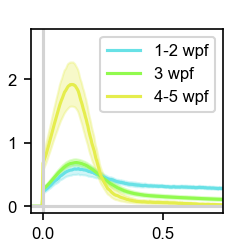

In [28]:
# --- Plot settings ---
default()
widget()
arial()
cm_to_inch = 1 / 2.54
fig_width_cm = 4.2 
fig_height_cm = 4.05 

fig = plt.figure(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch), dpi=150)


# --- Time axis ---
dt = 1 / 300
t_before = 0.1
i_before = round(t_before / dt)
total_points = len(mean_mean_y)
time = np.linspace(-i_before * dt, (total_points - i_before - 1) * dt, total_points)

# --- Plot Young group ---
plt.plot(time, mean_mean_y, color=color_low_eta, label='1-2 wpf')
plt.fill_between(time, mean_mean_y - sem_mean_y, mean_mean_y + sem_mean_y, color=color_low_eta, alpha=0.3)


# --- Plot Intermediate group --- mean_mean_mix, sem_mean_mix
plt.plot(time, mean_mean_i, color=color_m, label='3 wpf')
plt.fill_between(time, mean_mean_i - sem_mean_i, mean_mean_i + sem_mean_i, color=color_m, alpha=0.3)

# --- Plot Old group ---mean_mean_bout, sem_mean_bout
plt.plot(time, mean_mean_o, color=color_high_eta, label='4-5 wpf')
plt.fill_between(time, mean_mean_o - sem_mean_o, mean_mean_o + sem_mean_o, color=color_high_eta, alpha=0.3)


# --- Axis formatting ---
plt.axhline(0, color='lightgray')
plt.axvline(0, color='lightgray')
plt.xlim(-0.05,0.75)
plt.xticks([0, 0.5])
plt.xlabel('time (s)')
plt.ylim(-1,28)
plt.yticks([0, 10, 20], ['0', '1', '2'])
plt.ylabel(r'$v$ (cm/s)')

plt.legend()

fig.savefig(os.path.join(path_figures, "Fig_S7a_onset_speed_age_all_fish_mean_0before.pdf"), format="pdf")
fig.savefig(os.path.join(path_media, "Fig_S7a_onset_speed_age_all_fish_mean_0before.pdf"), format="pdf", bbox_inches='tight', dpi=200)
plt.show()

## sort by boutID

In [94]:
# --- Colors for groups ---
color_low_eta = '#dc267f'
color_medium_eta = '#fe6100'
color_high_eta = '#ffb000'

In [95]:
vfish_c_onsets_tot_cont = extract_speed_onsets(index_cont, vfish_c_list, onset_indices_list, bout_duration_list)
vfish_c_onsets_tot_mix = extract_speed_onsets(index_mix, vfish_c_list, onset_indices_list, bout_duration_list)
vfish_c_onsets_tot_bout = extract_speed_onsets(index_bout, vfish_c_list, onset_indices_list, bout_duration_list)

#pooled statistics
mean_pooled_cont, sem_pooled_cont, std_pooled_cont, med_pooled_cont, iqr_l_pooled_cont, iqr_u_pooled_cont = compute_pooledstats_vfis_onset(vfish_c_onsets_tot_cont)
mean_pooled_mix, sem_pooled_mix, std_pooled_mix, med_pooled_mix, iqr_l_pooled_mix, iqr_u_pooled_mix = compute_pooledstats_vfis_onset(vfish_c_onsets_tot_mix)
mean_pooled_bout, sem_pooled_bout, std_pooled_bout, med_pooled_bout, iqr_l_pooled_bout, iqr_u_pooled_bout = compute_pooledstats_vfis_onset(vfish_c_onsets_tot_bout)

#across-fish statistics
mean_mean_cont, sem_mean_cont, mean_median_cont, sem_median_cont  = compute_stats_vfish_onset_across_fish(vfish_c_onsets_tot_cont)
mean_mean_mix, sem_mean_mix, mean_median_mix, sem_median_mix  = compute_stats_vfish_onset_across_fish(vfish_c_onsets_tot_mix)
mean_mean_bout, sem_mean_bout, mean_median_bout, sem_median_bout  = compute_stats_vfish_onset_across_fish(vfish_c_onsets_tot_bout)

In [96]:
len(vfish_c_onsets_tot_cont), len(vfish_c_onsets_tot_mix), len(vfish_c_onsets_tot_bout)

(4, 11, 5)

Peak (young) at t=0.143 s, value=5.039
Peak (intermediate) at t=0.137 s, value=6.657
Peak (old) at t=0.117 s, value=11.458


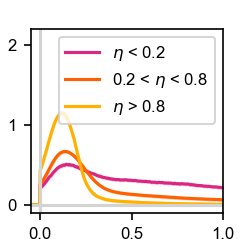

In [97]:
# --- Plot settings ---
default()
widget()
arial()
cm_to_inch = 1 / 2.54
fig_width_cm = 4.2 
fig_height_cm = 4.05 

fig = plt.figure(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch), dpi=150)


# --- Time axis ---
dt = 1 / 300
t_before = 0.1
i_before = round(t_before / dt)
total_points = len(mean_pooled_cont)
time = np.linspace(-i_before * dt, (total_points - i_before - 1) * dt, total_points)

# --- Plot Young group ---
plt.plot(time, mean_pooled_cont, color=color_low_eta, label=r'$\eta$ < 0.2')
plt.fill_between(time, mean_pooled_cont - sem_pooled_cont, mean_pooled_cont + sem_pooled_cont, color=color_low_eta, alpha=0.3)

max_idx_y = np.argmax(mean_pooled_cont)
print(f"Peak (young) at t={time[max_idx_y]:.3f} s, value={mean_pooled_cont[max_idx_y]:.3f}")

# --- Plot Intermediate group ---
plt.plot(time, mean_pooled_mix, color=color_medium_eta, label=r'0.2 < $\eta$ < 0.8')
plt.fill_between(time, mean_pooled_mix - sem_pooled_cont, mean_pooled_mix + sem_pooled_cont, color=color_medium_eta, alpha=0.3)

max_idx_i = np.argmax(mean_pooled_mix)
print(f"Peak (intermediate) at t={time[max_idx_i]:.3f} s, value={mean_pooled_mix[max_idx_i]:.3f}")

# --- Plot Old group ---
plt.plot(time, mean_pooled_bout, color=color_high_eta, label=r'$\eta$ > 0.8')
plt.fill_between(time, mean_pooled_bout - sem_pooled_cont, mean_pooled_bout + sem_pooled_cont, color=color_high_eta, alpha=0.3)

max_idx_o = np.argmax(mean_pooled_bout)
print(f"Peak (old) at t={time[max_idx_o]:.3f} s, value={mean_pooled_bout[max_idx_o]:.3f}")

# --- Axis formatting ---
plt.axhline(0, color='lightgray')
plt.axvline(0, color='lightgray')
plt.xlim(-0.05,1)
plt.xticks([0, 0.5, 1])
plt.xlabel('time (s)')
plt.ylim(-1,22)
plt.yticks([0, 10, 20], ['0', '1', '2'])
plt.ylabel(r'$v$ (cm/s)')

plt.legend()

#fig.savefig(os.path.join(path_figures, "initial_speed_boutID_all_fish_mean_0before.pdf"), format="pdf")
plt.show()

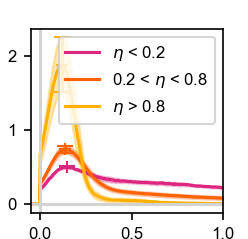

{'group': 'young', 't_peak': 0.14666666666666667, 'v_peak': 5.041048341760499, 't_err': 0, 'v_err': 0.06547246410009752}
{'group': 'intermediate', 't_peak': 0.13333333333333333, 'v_peak': 7.405583027604644, 't_err': 0, 'v_err': 0.5134265787678577}
{'group': 'old', 't_peak': 0.12, 'v_peak': 18.85470149060185, 't_err': 0, 'v_err': 3.745039477509846}


In [99]:
# --- Plot settings ---
default()
widget()
arial()
cm_to_inch = 1 / 2.54
fig_width_cm = 4.2 
fig_height_cm = 4.05 

fig = plt.figure(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch), dpi=150)

# --- Time axis ---
dt = 1 / 300
t_before = 0.1
i_before = round(t_before / dt)
total_points = len(mean_mean_cont)
time = np.linspace(-i_before * dt, (total_points - i_before - 1) * dt, total_points)

# --- Peak summary list ---
peak_summary = []

# --- Plot Young group ---
plt.plot(time, mean_mean_cont, color=color_low_eta, label=r'$\eta$ < 0.2')
plt.fill_between(time, mean_mean_cont - sem_mean_cont, mean_mean_cont + sem_mean_cont, color=color_low_eta, alpha=0.3)
idx = np.argmax(mean_mean_cont)
t_peak = time[idx]
v_peak = mean_mean_cont[idx]
sem_v = sem_mean_cont[idx]
peak_summary.append({
    'group': 'young',
    't_peak': t_peak,
    'v_peak': v_peak,
    't_err': 0,
    'v_err': sem_v
})
plt.errorbar(t_peak, v_peak, yerr=sem_v, fmt='+', color=color_low_eta, capsize=4)

# --- Plot Intermediate group ---
plt.plot(time, mean_mean_mix, color=color_medium_eta, label=r'0.2 < $\eta$ < 0.8')
plt.fill_between(time, mean_mean_mix - sem_mean_mix, mean_mean_mix + sem_mean_mix, color=color_medium_eta, alpha=0.3)
idx = np.argmax(mean_mean_mix)
t_peak = time[idx]
v_peak = mean_mean_mix[idx]
sem_v = sem_mean_mix[idx]
peak_summary.append({
    'group': 'intermediate',
    't_peak': t_peak,
    'v_peak': v_peak,
    't_err': 0,
    'v_err': sem_v
})
plt.errorbar(t_peak, v_peak, yerr=sem_v, fmt='+', color=color_medium_eta, capsize=4)

# --- Plot Old group ---
plt.plot(time, mean_mean_bout, color=color_high_eta, label=r'$\eta$ > 0.8')
plt.fill_between(time, mean_mean_bout - sem_mean_bout, mean_mean_bout + sem_mean_bout, color=color_high_eta, alpha=0.3)
idx = np.argmax(mean_mean_bout)
t_peak = time[idx]
v_peak = mean_mean_bout[idx]
sem_v = sem_mean_bout[idx]
peak_summary.append({
    'group': 'old',
    't_peak': t_peak,
    'v_peak': v_peak,
    't_err': 0,
    'v_err': sem_v
})
plt.errorbar(t_peak, v_peak, yerr=sem_v, fmt='+', color=color_high_eta, capsize=4)

# --- Axis formatting ---
plt.axhline(0, color='lightgray')
plt.axvline(0, color='lightgray')
plt.xlim(-0.05, 1)
plt.xticks([0, 0.5, 1])
plt.xlabel('time (s)')
#plt.ylim(-1, 28)
plt.yticks([0, 10, 20], ['0', '1', '2'])
plt.ylabel(r'$v$ (cm/s)')
plt.legend()

fig.savefig(os.path.join(path_figures, "Fig_3a_onset_speed_eta_all_fish_mean.pdf"), format="pdf")
fig.savefig(os.path.join(path_media, "Fig_3a_onset_speed_eta_all_fish_mean.pdf"), format="pdf", bbox_inches='tight', dpi=200)

plt.show()

# --- Print peak summary ---
for item in peak_summary:
    print(item)

In [81]:
fish_stats_vfish_low_eta = {}
for i in range(len(vfish_c_onsets_tot_cont)):
    fish_id = fish_ids[index_cont[i]] 
    vfish_c_onsets_aux = vfish_c_onsets_tot_cont[i]
    med_fish_onsets = np.nanquantile(vfish_c_onsets_aux, 0.5, axis=0)
    iqp_fish_onsets = np.nanquantile(vfish_c_onsets_aux, 0.75, axis=0) - med_fish_onsets
    iqm_fish_onsets = med_fish_onsets - np.nanquantile(vfish_c_onsets_aux, 0.25, axis=0)
    mean_fish_onsetst = np.nanmean(vfish_c_onsets_aux, axis=0)
    std_fish_onsets = np.nanstd(vfish_c_onsets_aux, axis=0)
    fish_stats_vfish_low_eta[fish_id] = {
            'time_onset': time,
            'mean': mean_fish_onsetst,
            'std': std_fish_onsets,
            'median': med_fish_onsets,
            'iqr_minus': iqm_fish_onsets,
            'iqr_plus': iqp_fish_onsets}
    

fish_stats_vfish_medium_eta = {}
for i in range(len(vfish_c_onsets_tot_mix)):
    fish_id = fish_ids[index_mix[i]] 
    vfish_c_onsets_aux = vfish_c_onsets_tot_mix[i]
    med_fish_onsets = np.nanquantile(vfish_c_onsets_aux, 0.5, axis=0)
    iqp_fish_onsets = np.nanquantile(vfish_c_onsets_aux, 0.75, axis=0) - med_fish_onsets
    iqm_fish_onsets = med_fish_onsets - np.nanquantile(vfish_c_onsets_aux, 0.25, axis=0)
    mean_fish_onsetst = np.nanmean(vfish_c_onsets_aux, axis=0)
    std_fish_onsets = np.nanstd(vfish_c_onsets_aux, axis=0)
    fish_stats_vfish_medium_eta[fish_id] = {
            'time_onset': time,
            'mean': mean_fish_onsetst,
            'std': std_fish_onsets,
            'median': med_fish_onsets,
            'iqr_minus': iqm_fish_onsets,
            'iqr_plus': iqp_fish_onsets}

fish_stats_vfish_high_eta = {}
for i in range(len(vfish_c_onsets_tot_bout)):
    fish_id = fish_ids[index_bout[i]] 
    vfish_c_onsets_aux = vfish_c_onsets_tot_bout[i]
    med_fish_onsets = np.nanquantile(vfish_c_onsets_aux, 0.5, axis=0)
    iqp_fish_onsets = np.nanquantile(vfish_c_onsets_aux, 0.75, axis=0) - med_fish_onsets
    iqm_fish_onsets = med_fish_onsets - np.nanquantile(vfish_c_onsets_aux, 0.25, axis=0)
    mean_fish_onsetst = np.nanmean(vfish_c_onsets_aux, axis=0)
    std_fish_onsets = np.nanstd(vfish_c_onsets_aux, axis=0)
    fish_stats_vfish_high_eta[fish_id] = {
            'time_onset': time,
            'mean': mean_fish_onsetst,
            'std': std_fish_onsets,
            'median': med_fish_onsets,
            'iqr_minus': iqm_fish_onsets,
            'iqr_plus': iqp_fish_onsets}

In [35]:
len(fish_stats_vfish_low_eta)

4

In [36]:
len(fish_stats_vfish_medium_eta)

11

In [37]:
len(fish_stats_vfish_high_eta)

5

In [38]:
import pickle

with open(os.path.join(path_data, "vfish_low_eta_fishbyfish_stats.pkl"), "wb") as f:
    pickle.dump(fish_stats_vfish_low_eta, f)
    
with open(os.path.join(path_data, "vfish_medium_eta_fishbyfish_stats.pkl"), "wb") as f:
    pickle.dump(fish_stats_vfish_medium_eta, f)  
    
with open(os.path.join(path_data, "vfish_high_eta_fishbyfish_stats.pkl"), "wb") as f:
    pickle.dump(fish_stats_vfish_high_eta, f)  
    


## v-max/tau- sorted by eta

In [39]:
taus_old_list, vmax_old_list = extract_first_peak_times_and_values(vfish_c_onsets_tot_o)
taus_young_list, vmax_young_list = extract_first_peak_times_and_values(vfish_c_onsets_tot_y)
taus_medium_list, vmax_medium_list = extract_first_peak_times_and_values(vfish_c_onsets_tot_i)

In [40]:
i = 1

dt=1/300
t_before=0.1
t_after=1
sigma = 10
time = np.linspace(-i_before * dt, (total_points - i_before - 1) * dt, total_points)

@interact(n=(0,len(onset_indices_list[i])-1,1))
def plot(n=0):
    default()
    widget()
    fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=50)
    ax.axhline(0,color='lightgray')
    ax.axvline(0,color='lightgray')
    
    ax.plot(time, vfish_c_onsets_tot_o[i][n,:])
    
    smoothed = gaussian_filter1d(vfish_c_onsets_tot_o[i][n, :], sigma=sigma)
    ax.plot(time, smoothed, label='Gaussian filtered')
    

    ax.plot(taus_old_list[i][n], vmax_old_list[i][n], 'ro', label='First peak')

    plt.show()

interactive(children=(IntSlider(value=0, description='n', max=203), Output()), _dom_classes=('widget-interact'…

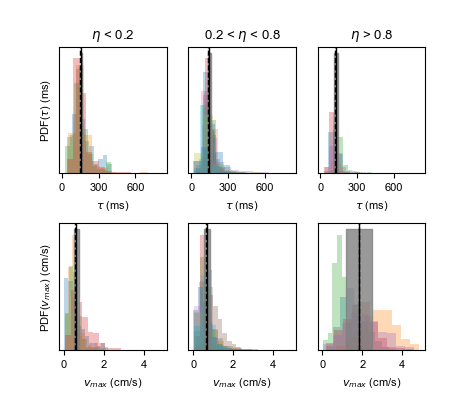

=== TAUS SUMMARY (mean across fish) ===
$\eta$ < 0.2 
: Mean of Means = 0.159, Mean of Medians = 0.144, Std of Means = 0.005
0.2 < $\eta$ < 0.8 
: Mean of Means = 0.148, Mean of Medians = 0.139, Std of Means = 0.012
$\eta$ > 0.8 
: Mean of Means = 0.125, Mean of Medians = 0.121, Std of Means = 0.016

=== VMAX SUMMARY (mean across fish) ===
$\eta$ < 0.2 
: Mean of Means = 6.276, Mean of Medians = 5.357, Std of Means = 1.452
0.2 < $\eta$ < 0.8 
: Mean of Means = 6.961, Mean of Medians = 6.252, Std of Means = 1.480
$\eta$ > 0.8 
: Mean of Means = 18.439, Mean of Medians = 18.217, Std of Means = 6.378


In [101]:
default()
widget()
arial()

cm_to_inch = 1 / 2.54
fig_width_cm = 12
fig_height_cm = 10


group_labels = [r'$\eta$ < 0.2', r'0.2 < $\eta$ < 0.8', r'$\eta$ > 0.8']
taus_lists = [taus_young_list, taus_medium_list, taus_old_list]
vmax_lists = [vmax_young_list, vmax_medium_list, vmax_old_list]

# Initialize summary containers
taus_summary = []
vmax_summary = []

fig, axs = plt.subplots(2, 3, figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch), dpi=100, sharex='row', gridspec_kw={'hspace': 0.4}  # Adjust this value as needed
)

for col in range(3):
    # --- TAUS ---
    per_fish_means = []
    per_fish_medians = []
    for data in taus_lists[col]:
        axs[0, col].hist(data, density=True, alpha=0.3)
        if len(data) > 0:
            per_fish_means.append(np.nanmean(data))
            per_fish_medians.append(np.nanmedian(data))
    mean_of_means = np.nanmean(per_fish_means)
    std_of_means = np.nanstd(per_fish_means)
    mean_of_medians = np.nanmean(per_fish_medians)
    taus_summary.append({'group': group_labels[col], 
                         'mean_of_means': mean_of_means, 'mean_of_medians': mean_of_medians, 'std_of_means': std_of_means})
    axs[0, col].axvline(mean_of_medians, color='black', linestyle='--', linewidth=1, label='Median')
    axs[0, col].axvline(mean_of_means, color='black', linestyle='-', linewidth=1, label='Mean')
    axs[0, col].fill_betweenx(
        y=[0, axs[0, col].get_ylim()[1]],
        x1=mean_of_means - std_of_means,
        x2=mean_of_means + std_of_means,
        color='gray',
        alpha=0.8,
        label='±1 STD'
    )
    axs[0, col].set_title(f'{group_labels[col]}')
    axs[0, col].set_xlabel(r'$\tau$ (ms)')
    axs[0, col].set_xticks([0,0.3, 0.6],[0,300, 600]) #ms
    axs[0, col].set_yticks([]) 

    # --- VMAX ---
    per_fish_means = []
    per_fish_medians = []
    for data in vmax_lists[col]:
        axs[1, col].hist(data, density=True, alpha=0.3)
        if len(data) > 0:
            per_fish_means.append(np.nanmean(data))
            per_fish_medians.append(np.nanmedian(data))
    mean_of_means = np.nanmean(per_fish_means)
    std_of_means = np.nanstd(per_fish_means)
    mean_of_medians = np.nanmean(per_fish_medians)
    vmax_summary.append({'group': group_labels[col], 
                         'mean_of_means': mean_of_means, 'mean_of_medians': mean_of_medians, 'std_of_means': std_of_means})
    axs[1, col].axvline(mean_of_medians, color='black', linestyle='--', linewidth=1, label='Median')
    axs[1, col].axvline(mean_of_means, color='black', linestyle='-', linewidth=1, label='Mean')
    axs[1, col].fill_betweenx(
        y=[0, axs[1, col].get_ylim()[1]],
        x1=mean_of_means - std_of_means,
        x2=mean_of_means + std_of_means,
        color='gray',
        alpha=0.8,
        label='±1 STD'
    )
    #axs[1, col].set_title(f'Vmax - {group_labels[col]}')
    axs[1, col].set_xlabel(r'$v_{max}$ (cm/s)')
    axs[1, col].set_xticks([0,20, 40],[0,2, 4]) #cm/s
    axs[1, col].set_yticks([]) 

# Y-axis labels
axs[0, 0].set_ylabel(r'PDF($\tau$) (ms)')
axs[1, 0].set_ylabel(r'PDF($v_{max}$) (cm/s)')


#fig.savefig(os.path.join(path_figures, "statistics_Vmax_taus_sorted_boutID_all_fish.pdf"), format="pdf")
#fig.savefig(os.path.join(path_media, "statistics_Vmax_taus_sorted_boutID_all_fish.pdf"), format="pdf", bbox_inches='tight', dpi=200)

plt.show()

# --- Print summaries ---
print("=== TAUS SUMMARY (mean across fish) ===")
for s in taus_summary:
    print(f"{s['group']} \n: Mean of Means = {s['mean_of_means']:.3f}, Mean of Medians = {s['mean_of_medians']:.3f}, Std of Means = {s['std_of_means']:.3f}")

print("\n=== VMAX SUMMARY (mean across fish) ===")
for s in vmax_summary:
    print(f"{s['group']} \n: Mean of Means = {s['mean_of_means']:.3f}, Mean of Medians = {s['mean_of_medians']:.3f}, Std of Means = {s['std_of_means']:.3f}")
    



# vtail: onset sorted by development

In [42]:
vtail_c_onsets_tot_y = extract_speed_onsets(index_y, vtail_c_list, onset_indices_list, bout_duration_list)
vtail_c_onsets_tot_i = extract_speed_onsets(index_i, vtail_c_list, onset_indices_list, bout_duration_list)
vtail_c_onsets_tot_o = extract_speed_onsets(index_o, vtail_c_list, onset_indices_list, bout_duration_list)

In [ ]:
# Compute pooled
mean_y, sem_y, std_y, med_y, iqr_l_y, iqr_u_y = compute_pooledstats_vfis_onset(vtail_c_onsets_tot_y)
mean_i, sem_i, std_i, med_i, iqr_l_i, iqr_u_i = compute_pooledstats_vfis_onset(vtail_c_onsets_tot_i)
mean_o, sem_o, std_o, med_o, iqr_l_o, iqr_u_o = compute_pooledstats_vfis_onset(vtail_c_onsets_tot_o)

#across-fish statistics
mean_mean_y, sem_mean_y, mean_median_y, sem_median_y = compute_stats_vfish_onset_across_fish(vtail_c_onsets_tot_y)
mean_mean_i, sem_mean_i, mean_median_i, sem_median_i = compute_stats_vfish_onset_across_fish(vtail_c_onsets_tot_i)
mean_mean_o, sem_mean_o, mean_median_o, sem_median_o  = compute_stats_vfish_onset_across_fish(vtail_c_onsets_tot_o)

[color_low_eta, color_m, color_high_eta, color_low_boutID, color_med_boutID, color_high_boutID, color_cont, color_bout] = get_colors()


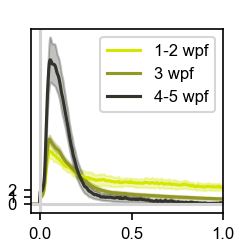

In [44]:
# --- Plot settings ---
default()
widget()
arial()
cm_to_inch = 1 / 2.54
fig_width_cm = 4.2 
fig_height_cm = 4.05 

fig = plt.figure(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch), dpi=150)


# --- Time axis ---
dt = 1 / 300
t_before = 0.1
i_before = round(t_before / dt)
total_points = len(mean_mean_y)
time = np.linspace(-i_before * dt, (total_points - i_before - 1) * dt, total_points)

# --- Plot Young group ---
plt.plot(time, mean_mean_y, color=color_low_eta, label='1-2 wpf')
plt.fill_between(time, mean_mean_y - sem_mean_y, mean_mean_y + sem_mean_y, color=color_low_eta, alpha=0.3)


# --- Plot Intermediate group --- mean_mean_mix, sem_mean_mix
plt.plot(time, mean_mean_i, color=color_m, label='3 wpf')
plt.fill_between(time, mean_mean_i - sem_mean_i, mean_mean_i + sem_mean_i, color=color_m, alpha=0.3)

# --- Plot Old group ---mean_mean_bout, sem_mean_bout
plt.plot(time, mean_mean_o, color=color_high_eta, label='4-5 wpf')
plt.fill_between(time, mean_mean_o - sem_mean_o, mean_mean_o + sem_mean_o, color=color_high_eta, alpha=0.3)


# --- Axis formatting ---
plt.axhline(0, color='lightgray')
plt.axvline(0, color='lightgray')
plt.xlim(-0.05,1)
plt.xticks([0, 0.5, 1])
plt.xlabel('time (s)')
#plt.ylim(-1,28)
plt.yticks([0, 10, 20], ['0', '1', '2'])
plt.ylabel(r'$v$ (cm/s)')

plt.legend()

#fig.savefig(os.path.join(path_figures, "initial_speedTAIL_age_all_fish_mean_0before.pdf"), format="pdf")
plt.show()

## sort by boutID

In [ ]:
# --- Colors for groups ---
color_low_eta = '#E60DDE'
color_low_eta = '#AD1FBD'
color_high_eta = '#613366'

In [46]:
vtail_c_onsets_tot_cont = extract_speed_onsets(index_cont, vtail_c_list, onset_indices_list, bout_duration_list)
vtail_c_onsets_tot_mix = extract_speed_onsets(index_mix, vtail_c_list, onset_indices_list, bout_duration_list)
vtail_c_onsets_tot_bout = extract_speed_onsets(index_bout, vtail_c_list, onset_indices_list, bout_duration_list)

#pooled statistics
mean_pooled_cont, sem_pooled_cont, std_pooled_cont, med_pooled_cont, iqr_l_pooled_cont, iqr_u_pooled_cont = compute_pooledstats_vfis_onset(vtail_c_onsets_tot_cont)
mean_pooled_mix, sem_pooled_mix, std_pooled_mix, med_pooled_mix, iqr_l_pooled_mix, iqr_u_pooled_mix = compute_pooledstats_vfis_onset(vtail_c_onsets_tot_mix)
mean_pooled_bout, sem_pooled_bout, std_pooled_bout, med_pooled_bout, iqr_l_pooled_bout, iqr_u_pooled_bout = compute_pooledstats_vfis_onset(vtail_c_onsets_tot_bout)

#across-fish statistics
mean_mean_cont, sem_mean_cont, mean_median_cont, sem_median_cont  = compute_stats_vfish_onset_across_fish(vtail_c_onsets_tot_cont)
mean_mean_mix, sem_mean_mix, mean_median_mix, sem_median_mix  = compute_stats_vfish_onset_across_fish(vtail_c_onsets_tot_mix)
mean_mean_bout, sem_mean_bout, mean_median_bout, sem_median_bout  = compute_stats_vfish_onset_across_fish(vtail_c_onsets_tot_bout)

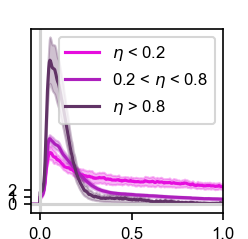

In [47]:
# --- Plot settings ---
default()
widget()
arial()
cm_to_inch = 1 / 2.54
fig_width_cm = 4.2 
fig_height_cm = 4.05 

fig = plt.figure(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch), dpi=150)


# --- Time axis ---
dt = 1 / 300
t_before = 0.1
i_before = round(t_before / dt)
total_points = len(mean_pooled_cont)
time = np.linspace(-i_before * dt, (total_points - i_before - 1) * dt, total_points)

# --- Plot Young group ---
plt.plot(time, mean_mean_cont, color=color_low_eta, label=r'$\eta$ < 0.2')
plt.fill_between(time, mean_mean_cont - sem_mean_cont, mean_mean_cont + sem_mean_cont, color=color_low_eta, alpha=0.3)


# --- Plot Intermediate group --- mean_mean_mix, sem_mean_mix
plt.plot(time, mean_mean_mix, color=color_low_eta, label=r'0.2 < $\eta$ < 0.8')
plt.fill_between(time, mean_mean_mix - sem_mean_mix, mean_mean_mix + sem_mean_mix, color=color_low_eta, alpha=0.3)

# --- Plot Old group ---mean_mean_bout, sem_mean_bout
plt.plot(time, mean_mean_bout, color=color_high_eta, label=r'$\eta$ > 0.8')
plt.fill_between(time, mean_mean_bout - sem_mean_bout, mean_mean_bout + sem_mean_bout, color=color_high_eta, alpha=0.3)


# --- Axis formatting ---
plt.axhline(0, color='lightgray')
plt.axvline(0, color='lightgray')
plt.xlim(-0.05,1)
plt.xticks([0, 0.5, 1])
plt.xlabel('time (s)')
#plt.ylim(-1,28)
plt.yticks([0, 10, 20], ['0', '1', '2'])
plt.ylabel(r'$v$ (cm/s)')

plt.legend()

#fig.savefig(os.path.join(path_figures, "initial_speedTAIL_boutID_all_fish_mean_0before.pdf"), format="pdf")
plt.show()

In [48]:
fish_stats_vtail_low_eta = {}
for i in range(len(vtail_c_onsets_tot_cont)):
    fish_id = fish_ids[index_cont[i]] 
    vtail_c_onsets_aux = vtail_c_onsets_tot_cont[i]
    med_fish_onsets = np.nanquantile(vtail_c_onsets_aux, 0.5, axis=0)
    iqp_fish_onsets = np.nanquantile(vtail_c_onsets_aux, 0.75, axis=0) - med_fish_onsets
    iqm_fish_onsets = med_fish_onsets - np.nanquantile(vtail_c_onsets_aux, 0.25, axis=0)
    mean_fish_onsetst = np.nanmean(vtail_c_onsets_aux, axis=0)
    std_fish_onsets = np.nanstd(vtail_c_onsets_aux, axis=0)
    fish_stats_vtail_low_eta[fish_id] = {
            'time_onset': time,
            'mean': mean_fish_onsetst,
            'std': std_fish_onsets,
            'median': med_fish_onsets,
            'iqr_minus': iqm_fish_onsets,
            'iqr_plus': iqp_fish_onsets}
    

fish_stats_vtail_medium_eta = {}
for i in range(len(vtail_c_onsets_tot_mix)):
    fish_id = fish_ids[index_mix[i]] 
    vtail_c_onsets_aux = vtail_c_onsets_tot_mix[i]
    med_fish_onsets = np.nanquantile(vtail_c_onsets_aux, 0.5, axis=0)
    iqp_fish_onsets = np.nanquantile(vtail_c_onsets_aux, 0.75, axis=0) - med_fish_onsets
    iqm_fish_onsets = med_fish_onsets - np.nanquantile(vtail_c_onsets_aux, 0.25, axis=0)
    mean_fish_onsetst = np.nanmean(vtail_c_onsets_aux, axis=0)
    std_fish_onsets = np.nanstd(vtail_c_onsets_aux, axis=0)
    fish_stats_vtail_medium_eta[fish_id] = {
            'time_onset': time,
            'mean': mean_fish_onsetst,
            'std': std_fish_onsets,
            'median': med_fish_onsets,
            'iqr_minus': iqm_fish_onsets,
            'iqr_plus': iqp_fish_onsets}

fish_stats_vtail_high_eta = {}
for i in range(len(vtail_c_onsets_tot_bout)):
    fish_id = fish_ids[index_bout[i]] 
    vtail_c_onsets_aux = vtail_c_onsets_tot_bout[i]
    med_fish_onsets = np.nanquantile(vtail_c_onsets_aux, 0.5, axis=0)
    iqp_fish_onsets = np.nanquantile(vtail_c_onsets_aux, 0.75, axis=0) - med_fish_onsets
    iqm_fish_onsets = med_fish_onsets - np.nanquantile(vtail_c_onsets_aux, 0.25, axis=0)
    mean_fish_onsetst = np.nanmean(vtail_c_onsets_aux, axis=0)
    std_fish_onsets = np.nanstd(vtail_c_onsets_aux, axis=0)
    fish_stats_vtail_high_eta[fish_id] = {
            'time_onset': time,
            'mean': mean_fish_onsetst,
            'std': std_fish_onsets,
            'median': med_fish_onsets,
            'iqr_minus': iqm_fish_onsets,
            'iqr_plus': iqp_fish_onsets}

In [49]:
len(fish_stats_vtail_low_eta)

4

In [50]:
len(fish_stats_vtail_medium_eta)

11

In [51]:
len(fish_stats_vtail_high_eta)

5

In [52]:
import pickle

with open(os.path.join(path_data, "vtail_low_eta_fishbyfish_stats.pkl"), "wb") as f:
    pickle.dump(fish_stats_vtail_low_eta, f)
    
with open(os.path.join(path_data, "vtail_medium_eta_fishbyfish_stats.pkl"), "wb") as f:
    pickle.dump(fish_stats_vtail_medium_eta, f)  
    
with open(os.path.join(path_data, "vtail_high_eta_fishbyfish_stats.pkl"), "wb") as f:
    pickle.dump(fish_stats_vtail_high_eta, f)  
    
